# Vision — Label Berisik (cari gambar yang salah label dengan cleanlab)
**Kapan dipakai:** label gambar dibuat manusia dan kamu curiga sebagian salah (kelas mirip
tertukar, anotator terburu-buru).

**Langkah:** embedding pretrained → probabilitas out-of-fold → cleanlab menandai gambar yang
labelnya bertentangan dengan tebakan model yang yakin → lihat grid → buang/perbaiki → latih
ulang.

**Data demo:** CIFAR-10 kecil. Sebagian label **sengaja ditukar** (kucing→anjing, mobil→truk,
rusa→kuda) supaya deteksinya bisa diukur. Saat lomba, hapus sel "Rusak sebagian label".

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from cleanlab.filter import find_label_issues
from PIL import Image
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from torch import nn
from torchvision import models

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/vision/classification/cifar10_small"  # GANTI
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TEST_CSV = f"{DATA_FOLDER}/test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/test_labels.csv"   # hanya ada di data latihan
PRETRAINED = "../../pretrained"

PATH_COL = "path"     # path gambar, relatif terhadap DATA_FOLDER
TARGET = "label"
SWAP_FRACTION = 0.4                                            # HANYA DEMO
SWAPS = {"cat": "dog", "automobile": "truck", "deer": "horse"}   # HANYA DEMO
IMAGE_SIZE = 224
BATCH_SIZE = 32
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"
MEAN = np.array([0.485, 0.456, 0.406])   # normalisasi warna ImageNet
STD = np.array([0.229, 0.224, 0.225])

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
print(train[TARGET].value_counts())

train: (4000, 2) | test: (1000, 2)
label
airplane      400
automobile    400
bird          400
cat           400
deer          400
dog           400
frog          400
horse         400
ship          400
truck         400
Name: count, dtype: int64


## Rusak sebagian label (HANYA DEMO, hapus sel ini saat lomba)

In [4]:
rng = np.random.default_rng(SEED)
true_labels = train[TARGET].to_numpy().copy()
noisy_labels = true_labels.copy()
for right_class in SWAPS:
    hit = (true_labels == right_class) & (rng.random(len(train)) < SWAP_FRACTION)
    noisy_labels[hit] = SWAPS[right_class]
train[TARGET] = noisy_labels
is_corrupted = noisy_labels != true_labels
print("label dirusak:", is_corrupted.sum())

label dirusak: 508


## Embedding ResNet18 pretrained (beku)

In [5]:
backbone = models.resnet18(weights=None)
backbone.load_state_dict(torch.load(f"{PRETRAINED}/resnet18/model.pth", map_location="cpu"))
backbone.fc = nn.Identity()
backbone = backbone.to(DEVICE)
backbone.eval()


def embed_images(paths):
    batches = []
    for start in range(0, len(paths), BATCH_SIZE):
        arrays = []
        for path in paths[start:start + BATCH_SIZE]:
            image = Image.open(f"{DATA_FOLDER}/{path}").convert("RGB")
            image = image.resize((IMAGE_SIZE, IMAGE_SIZE))
            arrays.append((np.asarray(image) / 255 - MEAN) / STD)
        batch = torch.tensor(np.stack(arrays), dtype=torch.float32)
        batch = batch.permute(0, 3, 1, 2).to(DEVICE)
        with torch.no_grad():
            batches.append(backbone(batch).cpu().numpy())
    return np.concatenate(batches)


X_train = embed_images(list(train[PATH_COL]))
X_test = embed_images(list(test[PATH_COL]))
print("train:", X_train.shape, "| test:", X_test.shape)

train: (4000, 512) | test: (1000, 512)


## Probabilitas out-of-fold lalu cari label bermasalah
Out-of-fold = tiap gambar ditebak oleh model yang tidak melihat gambar itu saat latih.
Pilih SATU model: hapus `#` di baris yang ingin dipakai. Model harus punya `predict_proba`.

In [6]:
encoder = LabelEncoder()
y = encoder.fit_transform(train[TARGET])     # nomor kelas 0, 1, 2, …

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5))
# model = KNeighborsClassifier(n_neighbors=10, metric="cosine")

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_proba = cross_val_predict(model, X_train, y, cv=folds, method="predict_proba")

issue_rows = find_label_issues(
    labels=y,
    pred_probs=oof_proba,
    return_indices_ranked_by="self_confidence",
    n_jobs=1,
)
print("dicurigai salah label:", len(issue_rows))

dicurigai salah label: 905


## Lihat 16 gambar paling mencurigakan
Judul: label tertulis → tebakan model. Kalau gambarnya jelas cocok dengan tebakan, labelnya
salah.

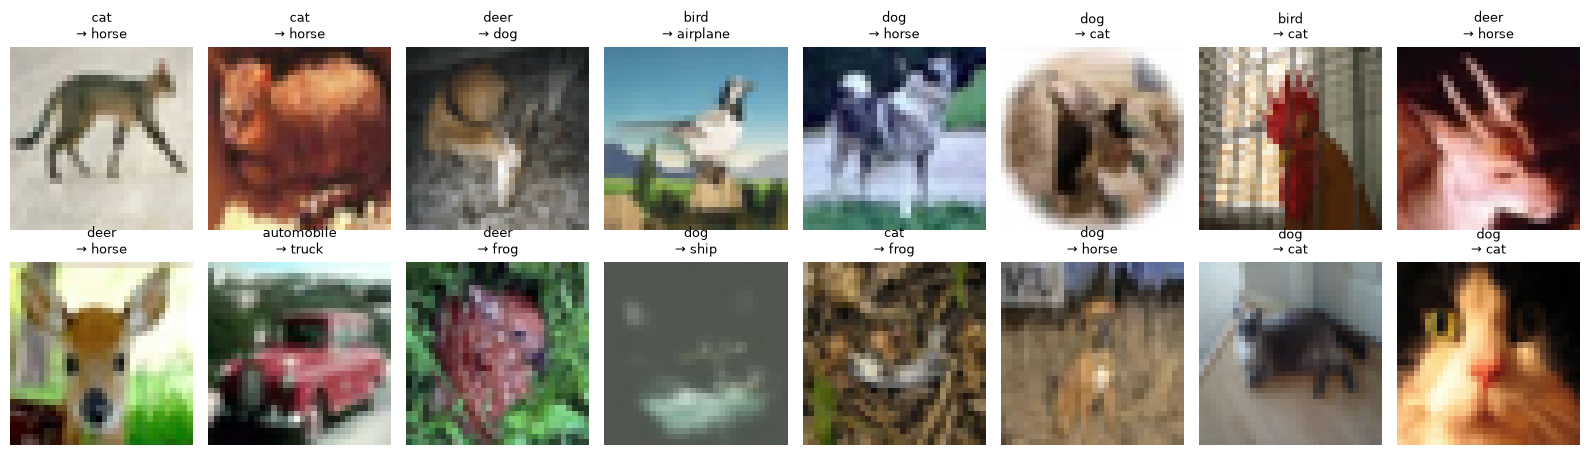

In [7]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for ax, row in zip(axes.ravel(), issue_rows[:16]):
    ax.imshow(Image.open(f"{DATA_FOLDER}/{train[PATH_COL][row]}"))
    guess = encoder.classes_[oof_proba[row].argmax()]
    ax.set_title(f"{train[TARGET][row]}\n→ {guess}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("dicurigai.png", dpi=150)
plt.show()

## Latih ulang tanpa baris bermasalah
Alternatif: perbaiki label (ganti dengan tebakan model) daripada membuang. Hapus `#` di 4 baris
alternatif di bawah.

In [8]:
keep = np.ones(len(train), dtype=bool)
keep[issue_rows] = False
clean_labels = train[TARGET].to_numpy()
# clean_labels = train[TARGET].to_numpy().copy()
# for row in issue_rows:
#     clean_labels[row] = encoder.classes_[oof_proba[row].argmax()]
# keep = np.ones(len(train), dtype=bool)

clean_model = clone(model)
clean_model.fit(X_train[keep], clean_labels[keep])
print("baris dipakai:", keep.sum(), "dari", len(train))

baris dipakai: 3095 dari 4000


## Submission

In [9]:
predictions = clean_model.predict(X_test)

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,label
0,1,deer
1,2,airplane
2,3,airplane
3,4,airplane
4,5,airplane


## Cek dengan kunci jawaban latihan (HAPUS saat lomba)
Seberapa tepat deteksi label rusak, dan apakah membersihkan label menaikkan skor test?

In [10]:
flagged = np.zeros(len(train), dtype=bool)
flagged[issue_rows] = True
print("precision deteksi:", round(precision_score(is_corrupted, flagged), 3))
print("recall deteksi   :", round(recall_score(is_corrupted, flagged), 3))

noisy_model = clone(model)
noisy_model.fit(X_train, train[TARGET])
test_key = pd.read_csv(TEST_KEY_CSV)[TARGET]
noisy_f1 = f1_score(test_key, noisy_model.predict(X_test), average="macro")
print("F1 macro test, label berisik     :", round(noisy_f1, 4))
print("F1 macro test, setelah dibersihkan:", round(f1_score(test_key, predictions,
                                                            average="macro"), 4))

precision deteksi: 0.282
recall deteksi   : 0.502


F1 macro test, label berisik     : 0.7116
F1 macro test, setelah dibersihkan: 0.7462
